# Niño4 SSTA and temperature-tendency integration

## Purpose

This notebook tests how well the model's Niño4 temperature tendency (`temp_tendency`) explains Niño4 sea-surface temperature anomalies (SSTA) in ACCESS-CM2 and ACCESS-OM2.

Two related—but different—comparisons are made:

1. **SSTA vs raw monthly TEND anomaly**: a simultaneous correlation between monthly SSTA and monthly `temp_tendency` after removing the monthly climatology from both variables.
2. **SSTA vs finite-integrated TEND**: `temp_tendency` is converted from monthly-mean W m$^{-2}$ to monthly heat input J m$^{-2}$ and summed over moving windows of 4–120 months. Each window sum is correlated with SSTA at the end of that window.

Both variables are reduced to the same Niño4 region (5°S–5°N, 160°E–210°E) using cosine-latitude area weighting. CM2 and OM2 are processed independently and only timestamps present in both the SST and heat-budget files are retained.

## Important comparison rule

All integration windows are evaluated over the same dates, beginning after the largest tested window (`MAX_WINDOW = 120`). This prevents short and long windows from being compared using different sample periods. A minimum of 120 valid monthly samples is required.

Changing `MAX_WINDOW` changes the common evaluation period. It should therefore be chosen before comparing results, not increased until a high correlation appears.

In [1]:
import os

# Change directory
os.chdir("/g/data/p66/ars599/work_ryan/final_analysis/review_internal")

# Verify
os.getcwd()


'/g/data/p66/ars599/work_ryan/final_analysis/review_internal'

## Part I — Real-model calculation

The next cell performs the ACCESS-CM2 and ACCESS-OM2 model-data analysis.

### SSTA

For each calendar month, the SST monthly climatology is removed:

$$
\mathrm{SSTA}(t)=\mathrm{SST}(t)-\overline{\mathrm{SST}}_{\mathrm{month}(t)}.
$$

### Tendency anomaly

The same monthly-climatology removal is applied to the raw Niño4 `temp_tendency`. The resulting simultaneous correlation describes the month-to-month relationship without integrating TEND.

### Finite integration

For an integration window of $N$ months:

$$
I_N(t)=\sum_{k=0}^{N-1}Q(t-k)\,\Delta t_{t-k},
$$

However, we didn't do it but just did a rolling sum:

$$
S_{i}^{9m}\left(t\right)=\sum_{k=0}^{8} Q_{i}(t-k);{\ Q}_{i}(t)\ [Wm-2];{\ S}_{i}(t)\ [Wm-2]
$$

where $Q$ is `temp_tendency` and $\Delta t$ is the number of seconds in each month. The notebook then calculates `corr(SSTA, I_N)` over a fixed common evaluation period.

A correlation below 1 is expected: surface SSTA and the diagnosed heat-budget tendency are related physical quantities, not two copies of the same time series. Mixing, advection, layer-depth differences, residual terms, and initial-condition effects all matter.


CM2: shared period 1850-01-16 to 2014-12-16, N=1980
CM2: SSTA vs raw TEND anomaly r=0.009
CM2: fixed evaluation N=1861, best integrated window=12 months, r=0.732


/jobfs/181350685.gadi-pbs/ipykernel_3987930/2205656599.py:31: FutureWarning: In a future version, xarray will not decode the variable 'average_DT' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xarray's default way of encoding timedelta64 values.
To continue decoding into a timedelta64 dtype, either set `decode_timedelta=True` when opening this dataset, or add the attribute `dtype='timedelta64[ns]'` to this variable on disk.
To opt-in to future behavior, set `decode_timedelta=False`.
  with xr.open_dataset(path) as ds:


OM2: shared period 1958-01-16 to 2014-12-16, N=684
OM2: SSTA vs raw TEND anomaly r=0.019
OM2: fixed evaluation N=565, best integrated window=72 months, r=0.794


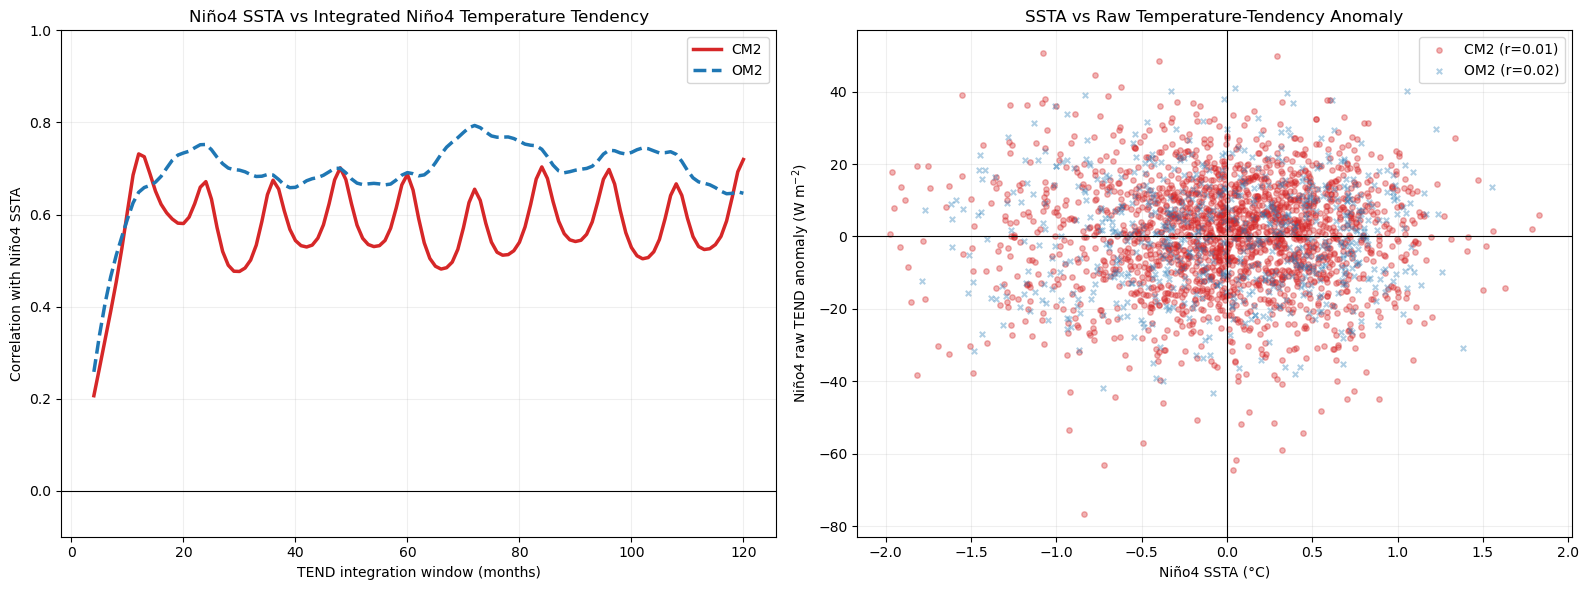

In [10]:
import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

# Avoid the optional flox/numba backend, which is incompatible with this environment.
xr.set_options(use_flox=False)

HB_FILES = {
    "CM2": "../data/processed_output/raw_integrated_data_CM2.nc",
    "OM2": "../data/processed_output/raw_integrated_data_OM2.nc",
}
SST_FILES = {
    "CM2": "../../atm_analysis/ocn_data/temp_Omon_bj594_piControl_r1i1p1_0001-0100_n96.nc",
    "OM2": "../../atm_analysis/ocn_data/pot_temp_Omon_om2_1deg_jra55_iaf_ars599_v1_piControl_r1i1p1_0001-0100_n96.nc",
}
SST_VARS = {"CM2": "temp", "OM2": "pot_temp"}
MAX_WINDOW = 120
MIN_SAMPLES = 120


def nino4_mean(da, lat_name, lon_name):
    da = da.assign_coords({lon_name: da[lon_name] % 360}).sortby(lon_name)
    lat_slice = slice(-5, 5) if da[lat_name][0] < da[lat_name][-1] else slice(5, -5)
    da = da.sel({lat_name: lat_slice, lon_name: slice(160, 210)})
    weights = np.cos(np.deg2rad(da[lat_name]))
    return da.weighted(weights).mean((lat_name, lon_name))


def load_nino4_ssta(path, var_name):
    with xr.open_dataset(path) as ds:
        da = ds[var_name]
        z_dims = [d for d in da.dims if d not in ("time", "lat", "lon", "yt_ocean", "xt_ocean")]
        if z_dims:
            da = da.isel({z_dims[0]: 0}, drop=True)
        lat_name = next(d for d in da.dims if "lat" in d.lower() or "yt" in d.lower())
        lon_name = next(d for d in da.dims if "lon" in d.lower() or "xt" in d.lower())
        sst = nino4_mean(da, lat_name, lon_name).load()
    monthly_clim = sst.groupby("time.month").mean("time")
    return sst.groupby("time.month") - monthly_clim


def load_nino4_tendency(path):
    with xr.open_dataset(path) as ds:
        da = ds["temp_tendency"]
        return nino4_mean(da, "lat", "lon").load()


results = {}
tendency_anom_results = {}
for model in ["CM2", "OM2"]:
    ssta = load_nino4_ssta(SST_FILES[model], SST_VARS[model])
    tendency = load_nino4_tendency(HB_FILES[model])

    # Keep only the genuinely shared timestamps for this model.
    ssta, tendency = xr.align(ssta, tendency, join="inner")
    if ssta.time.size == 0:
        raise ValueError(f"{model}: SSTA and temp_tendency have no common timestamps")

    # Raw monthly tendency anomaly: remove its monthly climatology.
    tendency_clim = tendency.groupby("time.month").mean("time")
    tendency_anom = tendency.groupby("time.month") - tendency_clim
    tendency_anom_results[model] = {
        "ssta": ssta,
        "tendency_anom": tendency_anom,
        "r": float(xr.corr(ssta, tendency_anom, dim="time")),
    }

    # Convert monthly mean W m-2 to monthly heat input J m-2.
    monthly_heat = tendency * tendency.time.dt.days_in_month * 86400

    if monthly_heat.time.size - MAX_WINDOW + 1 < MIN_SAMPLES:
        raise ValueError(
            f"{model}: only {monthly_heat.time.size} shared months; "
            f"MAX_WINDOW={MAX_WINDOW} leaves fewer than {MIN_SAMPLES} samples"
        )

    # Every window is evaluated over exactly the same dates.
    common_ssta = ssta.isel(time=slice(MAX_WINDOW - 1, None))
    rows = []
    for window in range(4, MAX_WINDOW + 1):
        finite_integral = monthly_heat.rolling(time=window, min_periods=window).sum()
        finite_common = finite_integral.isel(time=slice(MAX_WINDOW - 1, None))
        valid = np.isfinite(common_ssta) & np.isfinite(finite_common)
        n_valid = int(valid.sum())
        r = (float(xr.corr(common_ssta.where(valid), finite_common.where(valid), dim="time"))
             if n_valid >= MIN_SAMPLES else np.nan)
        rows.append((window, r, n_valid))

    results[model] = np.asarray(rows, dtype=float)
    best = results[model][np.nanargmax(results[model][:, 1])]
    print(f"{model}: shared period {str(ssta.time.values[0])[:10]} to "
          f"{str(ssta.time.values[-1])[:10]}, N={ssta.time.size}")
    print(f"{model}: SSTA vs raw TEND anomaly r={tendency_anom_results[model]['r']:.3f}")
    print(f"{model}: fixed evaluation N={int(best[2])}, "
          f"best integrated window={int(best[0])} months, r={best[1]:.3f}")


fig, axes = plt.subplots(1, 2, figsize=(16, 6))
ax = axes[0]
for model, color, ls in [("CM2", "tab:red", "-"), ("OM2", "tab:blue", "--")]:
    r = results[model]
    ax.plot(r[:, 0], r[:, 1], color=color, ls=ls, lw=2.5, label=model)

ax.set(xlabel="TEND integration window (months)",
       ylabel="Correlation with Niño4 SSTA",
       title="Niño4 SSTA vs Integrated Niño4 Temperature Tendency",
       ylim=(-0.1, 1))
ax.axhline(0, color="k", lw=0.8)
ax.grid(alpha=0.2)
ax.legend()

ax = axes[1]
for model, color, marker in [("CM2", "tab:red", "o"), ("OM2", "tab:blue", "x")]:
    item = tendency_anom_results[model]
    ax.scatter(item["ssta"], item["tendency_anom"], s=15, alpha=0.35,
               color=color, marker=marker, label=f"{model} (r={item['r']:.2f})")
ax.set(xlabel="Niño4 SSTA (°C)",
       ylabel=r"Niño4 raw TEND anomaly (W m$^{-2}$)",
       title="SSTA vs Raw Temperature-Tendency Anomaly")
ax.axhline(0, color="k", lw=0.8)
ax.axvline(0, color="k", lw=0.8)
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/nino4_ssta_vs_tendency_anomaly_and_integration.png",
            dpi=300, bbox_inches="tight")
plt.show()


### Reading the model-data figure

- **Left panel:** correlation between Niño4 SSTA and the finite TEND integral as a function of integration-window length. Compare the shape and peak location, not only the largest coefficient.
- **Right panel:** simultaneous relationship between Niño4 SSTA and raw monthly TEND anomaly. Each point is one shared month.
- The reported “best window” is only the maximum among the predeclared 4–120 month windows; it is not automatically a physically optimal or statistically significant timescale.
- Serial autocorrelation reduces the effective number of independent observations. These Pearson correlations should not be interpreted as significance tests without an autocorrelation-aware test.


## Part II — Synthetic signal and variable definitions

The complete synthetic monthly tendency is

$$
Q_{\mathrm{full}}(t)
= 8\sin\!\left(\frac{2\pi t}{40}\right)
+ 5\sin\!\left(\frac{2\pi t}{12}\right)
+ 3\sin\!\left(\frac{2\pi t}{55}\right)
+ \epsilon(t)+0.15,
$$

where $\epsilon(t)\sim\mathcal{N}(0,3^2)$. In the physical analogy,

$$
Q_{\mathrm{full}}(t)\ \longleftrightarrow\ \frac{dT}{dt},
\qquad
S_{\mathrm{full}}(t)=\sum_{\tau=0}^{t}Q_{\mathrm{full}}(\tau)\ \longleftrightarrow\ T(t).
$$

Thus, `Q_full` is the monthly tendency/increment and `S_full` is the cumulative temperature-like state. A trailing $N$-month sum of $Q$ represents a finite-period change $\Delta T_N$, not the instantaneous tendency itself.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reproducible 30-year monthly synthetic series.
np.random.seed(42)
n_months = 360
time = pd.date_range("2000-01-01", periods=n_months, freq="MS")
t = np.arange(n_months)

AMP_40 = 8.0
AMP_12 = 5.0
AMP_55 = 3.0
NOISE_STD = 3.0
MEAN_OFFSET = 0.15

signal_40 = pd.Series(AMP_40 * np.sin(2 * np.pi * t / 40), index=time)
signal_12 = pd.Series(AMP_12 * np.sin(2 * np.pi * t / 12), index=time)
signal_55 = pd.Series(AMP_55 * np.sin(2 * np.pi * t / 55), index=time)
noise = pd.Series(np.random.normal(0, NOISE_STD, n_months), index=time)

# Complete synthetic tendency and one-component-removed variants.
Q_full = signal_40 + signal_12 + signal_55 + noise + MEAN_OFFSET
Q_without_12 = Q_full - signal_12
Q_without_40 = Q_full - signal_40
Q_without_55 = Q_full - signal_55

# Fixed target: cumulative temperature-like state from the complete Q_full.
S_full = Q_full.cumsum()




### Time-series overlay: full integration and selected finite windows

The black line is the full cumulative target $S_{\mathrm{full}}$ ($T$-like state). The colored lines are trailing 3-, 6-, 9-, and 12-month sums of the same raw $Q_{\mathrm{full}}$. Each series is standardized separately only so that their timing and shape can be compared on one axis; the legend correlations are calculated from the unstandardized data.


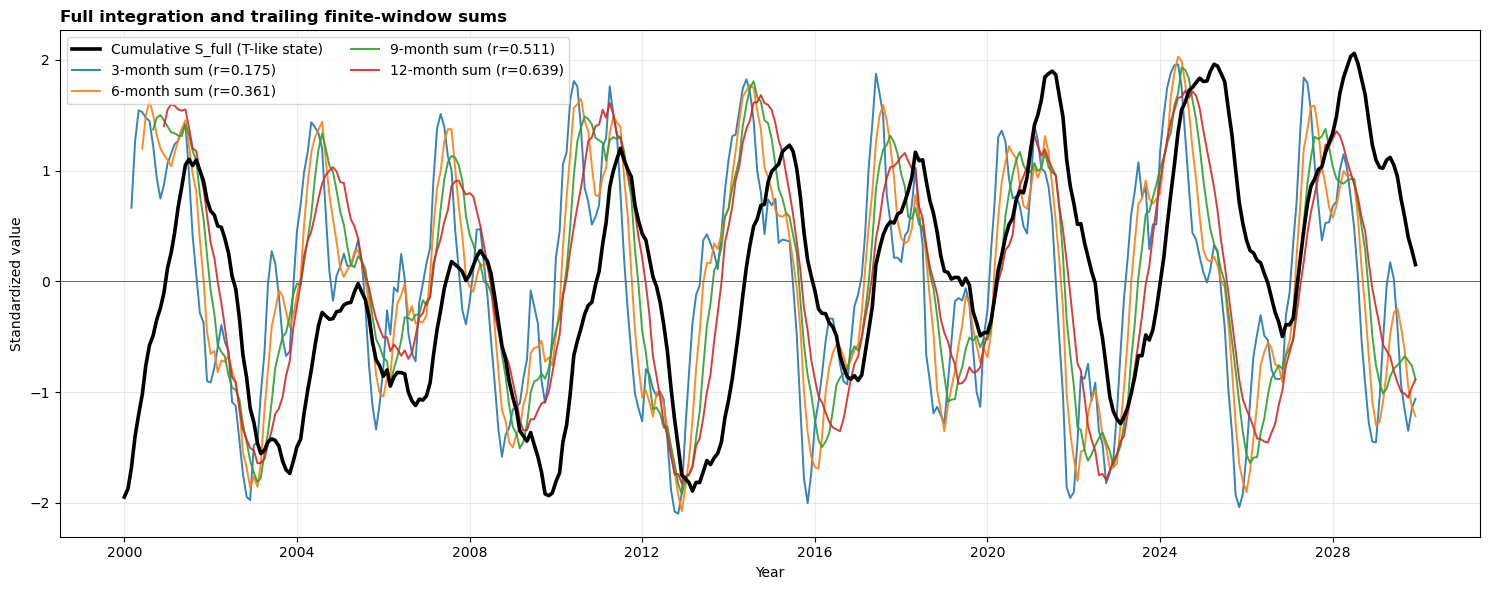

In [4]:
# Time-series overlay requested for direct visual comparison.
selected_windows = [3, 6, 9, 12]
selected_colors = {3: "tab:blue", 6: "tab:orange", 9: "tab:green", 12: "tab:red"}

fig, ax = plt.subplots(figsize=(15, 6))

S_plot = (S_full - S_full.mean()) / S_full.std()
ax.plot(S_plot.index, S_plot, color="black", lw=2.6,
        label="Cumulative S_full (T-like state)", zorder=5)

for window in selected_windows:
    finite_sum = Q_full.rolling(window, min_periods=window).sum().dropna()
    finite_z = (finite_sum - finite_sum.mean()) / finite_sum.std()
    r_value = finite_sum.corr(S_full.loc[finite_sum.index])
    ax.plot(finite_z.index, finite_z, color=selected_colors[window], lw=1.4,
            alpha=0.9, label=f"{window}-month sum (r={r_value:.3f})")

ax.axhline(0, color="0.4", lw=0.7)
ax.set_title("Full integration and trailing finite-window sums",
             loc="left", fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("Standardized value")
ax.grid(alpha=0.25)
ax.legend(ncol=2, fontsize=10)
plt.tight_layout()
plt.savefig("figures/dummy_full_integration_with_3_6_9_12_timeseries.png",
            dpi=300, bbox_inches="tight")
plt.show()


## Part III — Finite-window integration and correlation

For every trailing window from 1 month to the longest window that still leaves at least three paired samples, calculate

$$
I_N(t)=\sum_{k=0}^{N-1}Q_{\mathrm{full}}(t-k)
$$

and plot

$$
r_N=\operatorname{corr}\!\left[I_N(t),S_{\mathrm{full}}(t)\right].
$$

The 3-, 6-, 9-, and 12-month results are highlighted on this single correlation curve. A 360-month rolling sum contains only one value, so its Pearson correlation is undefined. The separate point at 360 months is the full-integration reference $\operatorname{corr}(S_{\mathrm{full}},S_{\mathrm{full}})=1$, not another rolling-window estimate. Correlations near the right edge use very few samples and are therefore unstable; the lower panel reports their sample counts.


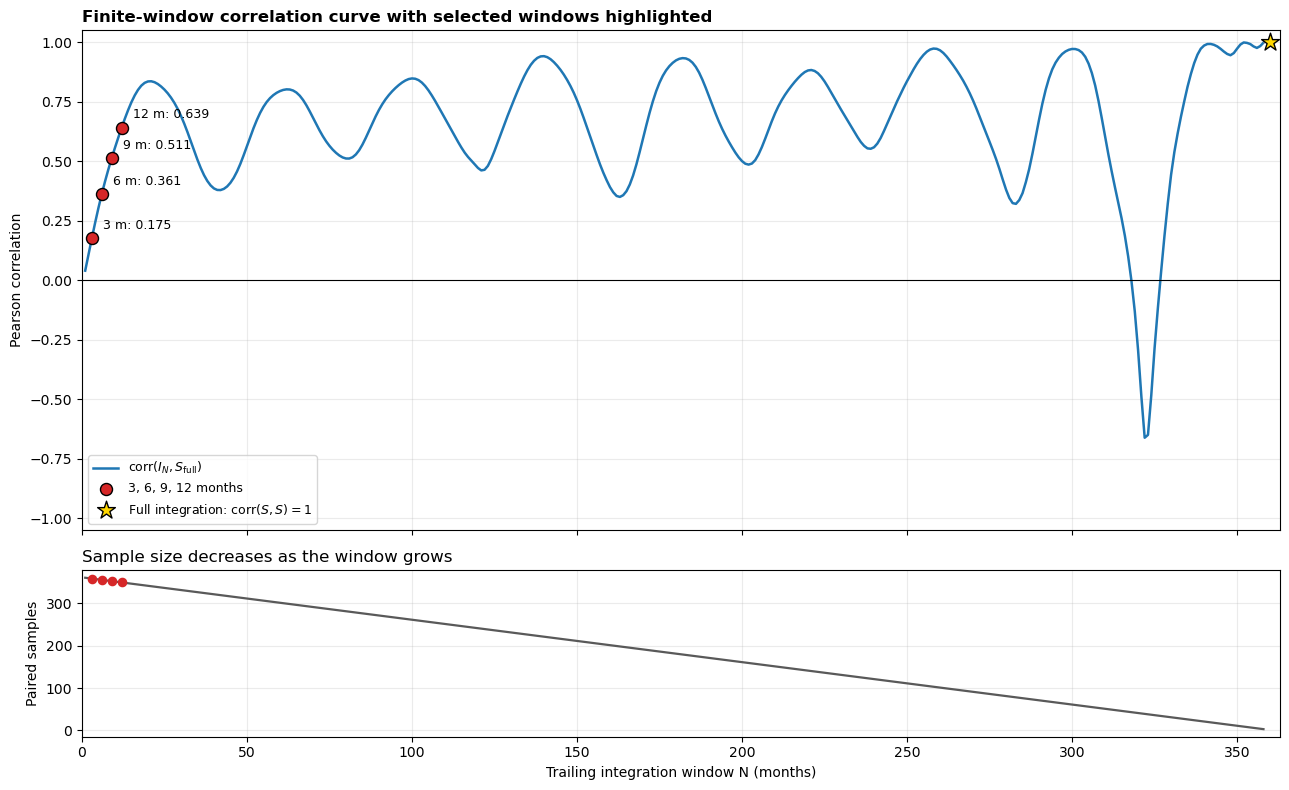

,window_months,correlation_with_S_full,paired_samples
0,3,0.175212,358
1,6,0.360831,355
2,9,0.511403,352
3,12,0.639306,349


Finite-window curve: N=1 to 358 months.
At N=360, rolling correlation is undefined (one sample only).
The full-integration star at r=1 is corr(S_full, S_full).


In [5]:
# Correlation curve from short rolling windows to the full-integration reference.
TOTAL_MONTHS = len(Q_full)
MIN_CORR_SAMPLES = 3
window_lengths = np.arange(1, TOTAL_MONTHS - MIN_CORR_SAMPLES + 2)

window_corr = []
window_samples = []
for window in window_lengths:
    finite_sum = Q_full.rolling(window, min_periods=window).sum().dropna()
    target = S_full.loc[finite_sum.index]
    window_corr.append(finite_sum.corr(target))
    window_samples.append(len(finite_sum))

window_corr = np.asarray(window_corr)
window_samples = np.asarray(window_samples)
highlight_windows = np.array([3, 6, 9, 12])
highlight_corr = window_corr[highlight_windows - 1]

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True,
                         gridspec_kw={"height_ratios": [3, 1]})

axes[0].plot(window_lengths, window_corr, color="tab:blue", lw=1.8,
             label=r"$\mathrm{corr}(I_N,S_{\mathrm{full}})$")
axes[0].scatter(highlight_windows, highlight_corr, s=75, color="tab:red",
                edgecolor="black", zorder=4, label="3, 6, 9, 12 months")
for window, value in zip(highlight_windows, highlight_corr):
    axes[0].annotate(f"{window} m: {value:.3f}", (window, value),
                     xytext=(8, 7), textcoords="offset points", fontsize=9)

# Full integration is S_full itself, so this is a reference point rather than
# a 360-month rolling correlation (which has only one sample and is undefined).
axes[0].scatter([TOTAL_MONTHS], [1.0], marker="*", s=180, color="gold",
                edgecolor="black", zorder=5,
                label=r"Full integration: $\mathrm{corr}(S,S)=1$")
axes[0].plot([window_lengths[-1], TOTAL_MONTHS],
             [window_corr[-1], 1.0], color="0.55", ls=":", lw=1)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_ylim(-1.05, 1.05)
axes[0].set_ylabel("Pearson correlation")
axes[0].set_title("Finite-window correlation curve with selected windows highlighted",
                  loc="left", fontweight="bold")
axes[0].grid(alpha=0.25)
axes[0].legend(fontsize=9, loc="best")

axes[1].plot(window_lengths, window_samples, color="0.35", lw=1.6)
axes[1].scatter(highlight_windows, window_samples[highlight_windows - 1],
                color="tab:red", s=35, zorder=3)
axes[1].set_xlim(0, TOTAL_MONTHS + 3)
axes[1].set_xlabel("Trailing integration window N (months)")
axes[1].set_ylabel("Paired samples")
axes[1].set_title("Sample size decreases as the window grows", loc="left")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.savefig("figures/dummy_window_correlation_curve_3_6_9_12_to_full.png",
            dpi=300, bbox_inches="tight")
plt.show()

selected_table = pd.DataFrame({
    "window_months": highlight_windows,
    "correlation_with_S_full": highlight_corr,
    "paired_samples": window_samples[highlight_windows - 1],
})
display(selected_table)
print(f"Finite-window curve: N=1 to {window_lengths[-1]} months.")
print(f"At N={TOTAL_MONTHS}, rolling correlation is undefined (one sample only).")
print("The full-integration star at r=1 is corr(S_full, S_full).")


## Part IV — Removing periodic components from the 9-month predictor

This experiment keeps one **fixed target**, the complete cumulative state

$$
S_{\mathrm{full}}(t)=\sum_{\tau=0}^{t}Q_{\mathrm{full}}(\tau)\ \longleftrightarrow\ T(t),
$$

while changing only the tendency used to construct the trailing 9-month $\Delta T$ predictor:

$$
Q_{-12}=Q_{\mathrm{full}}-5\sin\!\left(\frac{2\pi t}{12}\right),
$$

$$
Q_{-40}=Q_{\mathrm{full}}-8\sin\!\left(\frac{2\pi t}{40}\right),
\qquad
Q_{-55}=Q_{\mathrm{full}}-3\sin\!\left(\frac{2\pi t}{55}\right).
$$

Each $Q$ series first has its calendar-month climatology removed and is then summed over a trailing 9-month window. Therefore the plotted predictors are 9-month $\Delta T$ estimates, not raw $dT/dt$. All cases use identical timestamps and are correlated with the same fixed target `S_full`.


Periodic-component-removal comparison
----------------------------------------------------------
Full-Q 9-month ΔT           : r=0.5014, N=352
9-month ΔT without 12-month Q: r=0.5014, N=352
9-month ΔT without 40-month Q: r=0.2817, N=352
9-month ΔT without 55-month Q: r=0.4247, N=352
Change for 9-month ΔT without 12-month Q: -0.0000
Change for 9-month ΔT without 40-month Q: -0.2197
Change for 9-month ΔT without 55-month Q: -0.0767


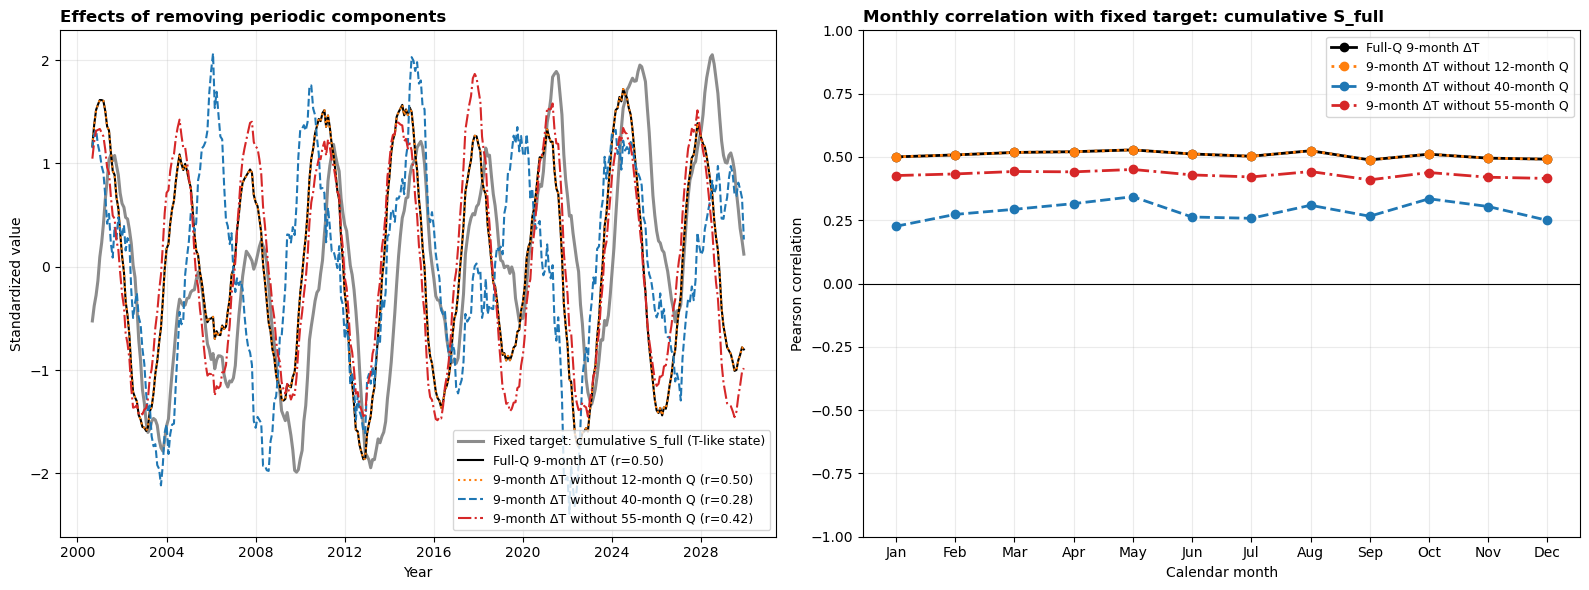

In [6]:
def monthly_anomaly_and_rolling9(series):
    climatology = series.groupby(series.index.month).transform("mean")
    anomaly = series - climatology
    return anomaly.rolling(9, min_periods=9).sum()


rolling9_full = monthly_anomaly_and_rolling9(Q_full)
rolling9_without_12 = monthly_anomaly_and_rolling9(Q_without_12)
rolling9_without_40 = monthly_anomaly_and_rolling9(Q_without_40)
rolling9_without_55 = monthly_anomaly_and_rolling9(Q_without_55)

# Use identical valid timestamps for both cases.
common_start = 8
target_common = S_full.iloc[common_start:]
rolling_cases = {
    "Full-Q 9-month ΔT": rolling9_full.iloc[common_start:],
    "9-month ΔT without 12-month Q": rolling9_without_12.iloc[common_start:],
    "9-month ΔT without 40-month Q": rolling9_without_40.iloc[common_start:],
    "9-month ΔT without 55-month Q": rolling9_without_55.iloc[common_start:],
}

overall_corr = {
    name: predictor.corr(target_common)
    for name, predictor in rolling_cases.items()
}
monthly_corr = {
    name: np.array([
        predictor[target_common.index.month == month].corr(
            target_common[target_common.index.month == month]
        )
        for month in range(1, 13)
    ])
    for name, predictor in rolling_cases.items()
}

print("Periodic-component-removal comparison")
print("-" * 58)
for name, r in overall_corr.items():
    print(f"{name:28s}: r={r:.4f}, N={len(target_common)}")
for name in ["9-month ΔT without 12-month Q", "9-month ΔT without 40-month Q", "9-month ΔT without 55-month Q"]:
    print(f"Change for {name}: {overall_corr[name] - overall_corr['Full-Q 9-month ΔT']:+.4f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
styles = {
    "Full-Q 9-month ΔT": ("black", "-"),
    "9-month ΔT without 12-month Q": ("tab:orange", ":"),
    "9-month ΔT without 40-month Q": ("tab:blue", "--"),
    "9-month ΔT without 55-month Q": ("tab:red", "-."),
}

# Standardize only for time-series display.
target_z = (target_common - target_common.mean()) / target_common.std()
axes[0].plot(target_z.index, target_z, color="0.55", lw=2.2,
             label="Fixed target: cumulative S_full (T-like state)")
for name, predictor in rolling_cases.items():
    color, ls = styles[name]
    z = (predictor - predictor.mean()) / predictor.std()
    axes[0].plot(z.index, z, color=color, ls=ls, lw=1.5,
                 label=f"{name} (r={overall_corr[name]:.2f})")
axes[0].set_title("Effects of removing periodic components", loc="left", fontweight="bold")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Standardized value")
axes[0].grid(alpha=0.25)
axes[0].legend(fontsize=9)

months = np.arange(1, 13)
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
for name, values in monthly_corr.items():
    color, ls = styles[name]
    axes[1].plot(months, values, color=color, ls=ls, marker="o", lw=2, label=name)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_title("Monthly correlation with fixed target: cumulative S_full", loc="left", fontweight="bold")
axes[1].set_xlabel("Calendar month")
axes[1].set_ylabel("Pearson correlation")
axes[1].set_xticks(months)
axes[1].set_xticklabels(month_labels)
axes[1].set_ylim(-1, 1)
axes[1].grid(alpha=0.25)
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig("figures/dummy_9month_component_removal_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()

### Component-removal results

All four predictors use the same fixed target, **cumulative `S_full` ($T$-like state)**, and the same 352 monthly timestamps.

| Trailing 9-month $\Delta T$ predictor | Overall correlation with `S_full` | Change from full-$Q$ predictor |
|---|---:|---:|
| Full-$Q$ 9-month $\Delta T$ | 0.5014 | — |
| 9-month $\Delta T$ without 12-month $Q$ | 0.5014 | 0.0000 |
| 9-month $\Delta T$ without 40-month $Q$ | 0.2817 | -0.2197 |
| 9-month $\Delta T$ without 55-month $Q$ | 0.4247 | -0.0767 |

The full-$Q$ and without-12-month curves overlap because removing the calendar-month climatology already eliminates the perfectly repeating 12-month seasonal component. Removing the 40-month component produces the largest reduction in this configuration; removing the 55-month component produces a smaller but clear reduction.

The calendar-month correlation ranges are:

- Full-$Q$ and without 12-month $Q$: approximately `0.488–0.528`.
- Without 40-month $Q$: approximately `0.226–0.343`.
- Without 55-month $Q$: approximately `0.409–0.451`.

The figure is `figures/dummy_9month_component_removal_comparison.png`.


## Part V — Supporting diagnostics

The remaining cells explain the distinction between monthly tendency $Q$, cumulative state $S$, and the lag-by-lag covariance contributions to the monthly 9-month-$\Delta T$ correlations.


### Monthly tendency $Q$ versus cumulative state $S$

Here, $Q_{\mathrm{full}}\leftrightarrow dT/dt$ and $S_{\mathrm{full}}\leftrightarrow T$. The numerical identity $S(t)-S(t-1)=Q(t)$ verifies that `S_full` is the cumulative state, not another tendency series.


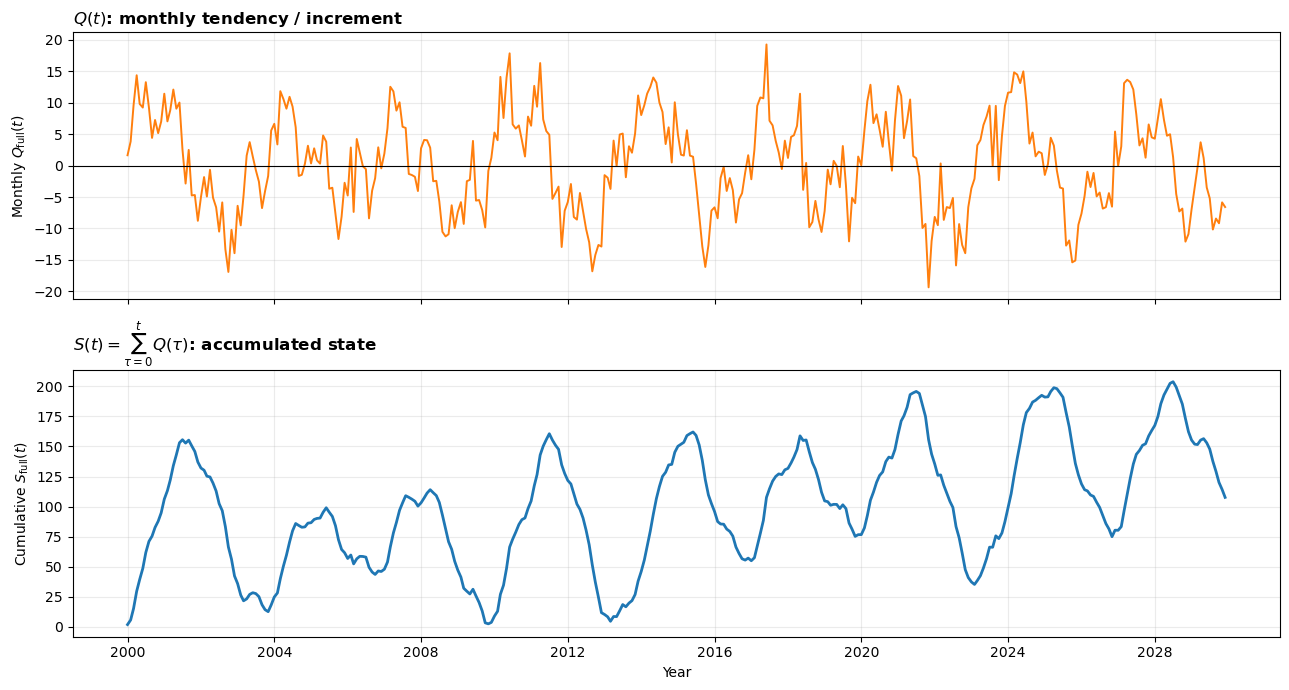

Check that S(t) - S(t-1) = Q(t): True


,Q_this_month,S_cumulative,change_in_S
2000-01-01,1.640142,1.640142,NaN
2000-02-01,3.828657,5.468800,3.828657
2000-03-01,9.574819,15.043618,9.574819
2000-04-01,14.359162,29.402780,14.359162
2000-05-01,9.803612,39.206392,9.803612
2000-06-01,9.226366,48.432758,9.226366


In [7]:
# Visual explanation: Q is a monthly increment; S is its cumulative state.
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

axes[0].plot(Q_full.index, Q_full, color="tab:orange", lw=1.4)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_ylabel(r"Monthly $Q_{\mathrm{full}}(t)$")
axes[0].set_title(r"$Q(t)$: monthly tendency / increment", loc="left", fontweight="bold")
axes[0].grid(alpha=0.25)

axes[1].plot(S_full.index, S_full, color="tab:blue", lw=2)
axes[1].set_ylabel(r"Cumulative $S_{\mathrm{full}}(t)$")
axes[1].set_xlabel("Year")
axes[1].set_title(r"$S(t)=\sum_{\tau=0}^{t}Q(\tau)$: accumulated state",
                  loc="left", fontweight="bold")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.savefig("figures/dummy_Q_vs_cumulative_S.png", dpi=300, bbox_inches="tight")
plt.show()

# Exact numerical check: the month-to-month change in S equals that month's Q.
delta_S = S_full.diff()
check = np.allclose(delta_S.iloc[1:], Q_full.iloc[1:])
print("Check that S(t) - S(t-1) = Q(t):", check)

# Display a short example so the distinction is explicit.
example = pd.DataFrame({
    "Q_this_month": Q_full,
    "S_cumulative": S_full,
    "change_in_S": delta_S,
}).iloc[:6]
display(example)


### Lag-by-lag support for the June–July dip

The blue curve alone does **not** prove that the complete June or July 9-month sum is out of phase. Each point combines nine lagged anomaly values. The diagnostic below uses the exact identity

$$
\operatorname{Cov}\!\left(S_t,\sum_{k=0}^{8}Q'_{t-k}\right)
=\sum_{k=0}^{8}\operatorname{Cov}(S_t,Q'_{t-k}).
$$

After division by the same standard deviations, the nine heat-map cells in each column sum exactly to that month's correlation. Red/positive cells reinforce the relationship; blue/negative cells cancel it. This separates an actual lag-by-lag cancellation explanation from a visual guess about phase. Because only about 29 samples contribute to each calendar month, some month-to-month variation also comes from finite-sample variability.

#### Reading columns and diagonals

For a given endpoint month, the **vertical sum of all nine cells** equals the correlation shown in the upper panel:

$$
r_m=\sum_{k=0}^{8}C_{m,k},
\qquad
C_{m,k}=\frac{\operatorname{Cov}(S_m,Q'_{m-k})}
{\sigma(S_m)\,\sigma(I_{9,m})}.
$$

The colors must be added algebraically: red cells are positive contributions and blue cells are negative contributions. For example, the nine cells in the May column sum to $r_{\mathrm{May}}=0.343$.

Cells along a diagonal need **not** have the same value. A diagonal can follow the same calendar month of $Q'$ while the cumulative `S_full` target endpoint advances. For example,

$$
\begin{aligned}
\text{May endpoint, lag 0:}&\quad Q'(\mathrm{May})\ \text{versus}\ S(\mathrm{May}),\\
\text{June endpoint, lag 1:}&\quad Q'(\mathrm{May})\ \text{versus}\ S(\mathrm{June}),\\
\text{July endpoint, lag 2:}&\quad Q'(\mathrm{May})\ \text{versus}\ S(\mathrm{July}).
\end{aligned}
$$

Thus, the $Q'$ calendar month can be the same along that diagonal, but both the target $S_m$ and the normalization $\sigma(S_m)\sigma(I_{9,m})$ change. Similar diagonal colors may indicate persistence, but equality is not required mathematically.

#### The same $Q'$ month can appear in different endpoint columns

The row label is relative to the endpoint month. Therefore two cells can contain the same calendar month of $Q'$ but compare it with different endpoint months of the cumulative target $S_{\mathrm{full}}$:

| Heat-map cell | Tendency month used | Cumulative target used |
|---|---|---|
| January column, `endpoint` | $Q'(\mathrm{January})$ | $S_{\mathrm{full}}(\mathrm{January})$ |
| February column, `1 month before` | $Q'(\mathrm{January})$ | $S_{\mathrm{full}}(\mathrm{February})$ |

Explicitly,

$$
C_{\mathrm{Jan},0}
=\frac{\operatorname{Cov}[S(\mathrm{Jan}),Q'(\mathrm{Jan})]}
{\sigma[S(\mathrm{Jan})]\,\sigma[I_9(\mathrm{Jan})]},
$$

whereas

$$
C_{\mathrm{Feb},1}
=\frac{\operatorname{Cov}[S(\mathrm{Feb}),Q'(\mathrm{Jan})]}
{\sigma[S(\mathrm{Feb})]\,\sigma[I_9(\mathrm{Feb})]}.
$$

They need not be equal because the target changes from January $S$ to February $S$, and the 9-month-sum normalization also changes. Each individual cell is a **contribution**, not a separate Pearson correlation. The algebraic sum of all nine cells in one vertical column is the Pearson correlation between that endpoint month's 9-month sum and that endpoint month's $S_{\mathrm{full}}$.


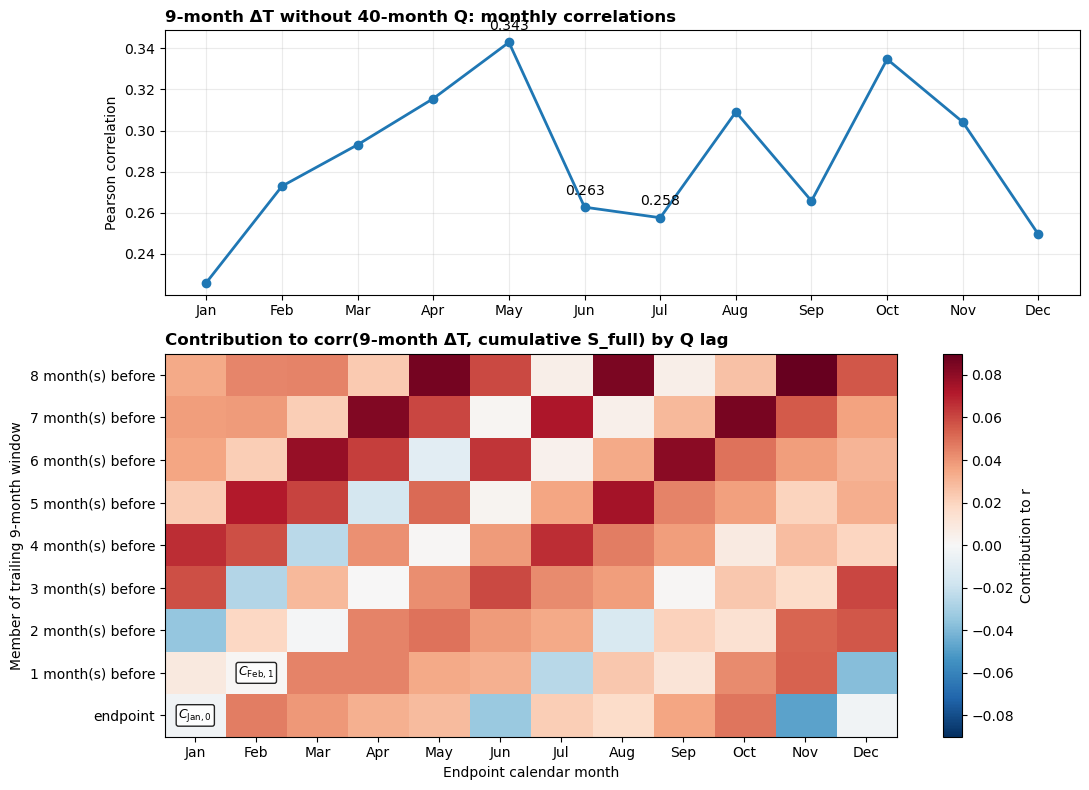

,month,correlation,sum_of_9_contributions
0,Jan,0.226051,0.226051
1,Feb,0.272965,0.272965
2,Mar,0.293130,0.293130
3,Apr,0.315572,0.315572
4,May,0.342942,0.342942
5,Jun,0.262735,0.262735
6,Jul,0.257591,0.257591
7,Aug,0.309058,0.309058
8,Sep,0.265757,0.265757
9,Oct,0.334748,0.334748


Exact check: sum of the 9 colored contributions equals each monthly correlation: True
May=0.343, June=0.263, July=0.258
Therefore, June/July are not identified as 'out of phase' from the line plot alone.
Negative heat-map cells are cancellation; positive cells reinforce the correlation.
Also note that January, not June or July, is the absolute minimum in this realization.


In [9]:
# Why does the monthly correlation change? Exact covariance decomposition.
# Focus: the 9-month ΔT predictor without the 40-month Q component (blue curve).
q_no40_anom = Q_without_40 - Q_without_40.groupby(Q_without_40.index.month).transform("mean")
x9_no40 = q_no40_anom.rolling(9, min_periods=9).sum()
y_fixed = S_full

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
monthly_r_check = []
lag_contribution = np.full((12, 9), np.nan)

for month in range(1, 13):
    endpoints = x9_no40.index[(x9_no40.index.month == month) & x9_no40.notna()]
    x = x9_no40.loc[endpoints]
    y = y_fixed.loc[endpoints]
    monthly_r_check.append(x.corr(y))

    # Since x(t) = sum[k=0..8] q'(t-k), Pearson r can be split exactly
    # into nine covariance contributions. Their sum equals corr(x, y).
    denominator = x.std(ddof=1) * y.std(ddof=1)
    for lag in range(9):
        q_lag = q_no40_anom.shift(lag).loc[endpoints]
        lag_contribution[month - 1, lag] = q_lag.cov(y) / denominator

monthly_r_check = np.asarray(monthly_r_check)
contribution_sum = lag_contribution.sum(axis=1)
assert np.allclose(contribution_sum, monthly_r_check)

fig, axes = plt.subplots(2, 1, figsize=(11, 8),
                         gridspec_kw={"height_ratios": [1, 1.45]})

# Panel (a): reproduce the blue monthly-correlation curve with exact values.
axes[0].plot(np.arange(12), monthly_r_check, color="tab:blue", marker="o", lw=2)
for idx in [4, 5, 6]:  # May, June, July
    axes[0].annotate(f"{monthly_r_check[idx]:.3f}", (idx, monthly_r_check[idx]),
                     xytext=(0, 9), textcoords="offset points", ha="center")
axes[0].set_xticks(np.arange(12), month_names)
axes[0].set_ylabel("Pearson correlation")
axes[0].set_title("9-month ΔT without 40-month Q: monthly correlations", loc="left", fontweight="bold")
axes[0].grid(alpha=0.25)

# Panel (b): contribution of each member of the 9-month window.
limit = np.nanmax(np.abs(lag_contribution))
im = axes[1].imshow(lag_contribution.T, aspect="auto", origin="lower",
                    cmap="RdBu_r", vmin=-limit, vmax=limit)

# Mark the two cells used in the Jan/Feb explanation below.
# Jan endpoint: x=0 (January), y=0 (endpoint).
# Feb one month before: x=1 (February), y=1 (one month before).
for x_pos, y_pos, label in [
    (0, 0, r"$C_{\mathrm{Jan},0}$"),
    (1, 1, r"$C_{\mathrm{Feb},1}$"),
]:
    axes[1].text(
        x_pos, y_pos, label, ha="center", va="center", fontsize=9,
        fontweight="bold", color="black",
        bbox=dict(boxstyle="round,pad=0.18", facecolor="white",
                  edgecolor="black", alpha=0.85),
    )
axes[1].set_xticks(np.arange(12), month_names)
axes[1].set_yticks(np.arange(9), ["endpoint" if k == 0 else f"{k} month(s) before" for k in range(9)])
axes[1].set_xlabel("Endpoint calendar month")
axes[1].set_ylabel("Member of trailing 9-month window")
axes[1].set_title("Contribution to corr(9-month ΔT, cumulative S_full) by Q lag",
                  loc="left", fontweight="bold")
fig.colorbar(im, ax=axes[1], label="Contribution to r")

plt.tight_layout()
plt.savefig("figures/dummy_monthly_corr_covariance_proof.png", dpi=300, bbox_inches="tight")
plt.show()

proof_table = pd.DataFrame({
    "month": month_names,
    "correlation": monthly_r_check,
    "sum_of_9_contributions": contribution_sum,
})
display(proof_table)

print("Exact check: sum of the 9 colored contributions equals each monthly correlation:",
      np.allclose(contribution_sum, monthly_r_check))
print(f"May={monthly_r_check[4]:.3f}, June={monthly_r_check[5]:.3f}, July={monthly_r_check[6]:.3f}")
print("Therefore, June/July are not identified as 'out of phase' from the line plot alone.")
print("Negative heat-map cells are cancellation; positive cells reinforce the correlation.")
print("Also note that January, not June or July, is the absolute minimum in this realization.")
